# ms.forward.glacier

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('ms.forward.glacier')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "ms.forward.glacier",
  "status": "recorded_results",
  "source_sha256": {
    "ms_glacier_32_molecules_20261116.json": "a4d084c72c7df758f49500942cdfcea91047cb3da3616b9adb93b5bc6e8470c6"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C/C1=C\\[C@@H](C)C/C=C/[C@H]2[C@@H]3O[C@]3(C)[C@@H](C)[C@H]3[C@H](Cc4c[nH]c5ccccc45)NC(=O)[C@]32C(=O)/C=C/C(=O)[C@@H]1O",
    "adduct": "[M+Na]+",
    "collision_energy": "35.0",
    "instrument": "Orbitrap",
    "precursor_mz": 551.2511
  },
  "sample_id": "MassSpecGymID0000403",
  "output": {
    "predicted_peaks_top100": {
      "length": 100,
      "first_values": [
        [
          67.0542266590246,
          0.011822191998362541
        ],
        [
          81.06987672302459,
          0.16171321272850037
        ],
        [
          83.0491412790246,
          0.008260359987616539
        ],
        [
          83.0855267569754,
          0.0016736892284825444
        ],
        [
          89.038576431729,
          0.00573704531416297
        ],
        [
          91.051820956,
          0.012795776128768921
        ],
        [
          93.06987673804919,
          0.24028274416923523
        ],
        [
          95.04914129404919,
   

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | cosine_similarity | 0.485717 |
| recorded evaluation | recorded model | entropy_similarity | 0.41328 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 1
}


## 预测／参考对照图

采用作者接口并显式提供采集条件，方法适配合理；31 条评分不足以证明广泛精度。先核查协议与训练重叠，再决定微调。

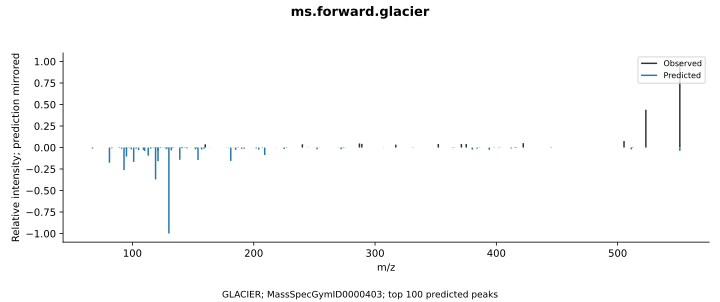

In [4]:
figure = render('ms.forward.glacier', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/ms-forward-glacier.md) · [Quick Start](../quickstart.md)
